# Контрастивное обучение с подкреплением: от будущих состояний к семантическим целям

**Разбор и исполняемая учебная реализация статьи** *Scaling Contrastive Reinforcement Learning to Open-Ended Environments*, анонимная рукопись ICLR 2027 из приложенного PDF.

Здесь можно пройти всю цепочку: **траектория → распределение меток → CRL-критик → действия → PPO-ученик**, посмотреть внутрь каждого шага и изменить параметры. Пояснения и комментарии — на русском.

Это реализация механизмов §3, а не воспроизведение таблиц Craftax. В статье: JAX, Craftax, до $10^9$ шагов и H100. Здесь: PyTorch, две небольшие полностью наблюдаемые среды, CPU, дискретные состояния и действия. Основной критик имеет обучаемые табличные эмбеддинги состояний и факторизованные головы целей: это сохраняет $f(s,a,g)=\phi(s,a)^\top\psi(g)$, но не проверяет обобщение на новые состояния. PPO использует отдельную нейросеть.

**Маршрут:** 1–3: теория и метки; 4–5: среды и визуализация; 6–8: обучение и абляции; 9: PPO + distillation; 10–12: интерактивная лаборатория, масштабирование, идеи экспериментов.

Первый запуск: выполните ячейки сверху вниз. Обучение занимает несколько минут на CPU; длительность зависит от машины. Готовые графики сохраняются прямо в `.ipynb`. Виджеты требуют Jupyter с поддержкой ipywidgets; все статические графики и обучение работают без них.

## 1. Зависимости и воспроизводимость

Нужны Python 3.10+, PyTorch 2.6+, NumPy, Matplotlib, IPython. `ipywidgets` нужен только для ползунков. Команда ниже необязательная: раскомментируйте её в новом окружении. Для CPU-версии PyTorch можно установить его отдельно с официального индекса `https://download.pytorch.org/whl/cpu`.

Не меняйте seed посередине сравнения: новые настройки проверяйте повторным запуском экспериментальных ячеек. CUDA намеренно не используется: задачи маленькие, и перенос данных может стоить дороже вычислений.

In [1]:
# При необходимости раскомментируйте и выполните один раз:
# %pip install "torch>=2.6" numpy matplotlib ipywidgets pillow

%matplotlib inline

import copy
import math
import time
from collections import deque
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.distributions import Categorical
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import animation
from IPython.display import display, HTML, Markdown

# Небольшим матрицам достаточно одного потока.
torch.set_num_threads(1)
DEVICE = torch.device("cpu")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 10})

def seed_all(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_all(0)
print("PyTorch:", torch.__version__, "| устройство:", DEVICE)

PyTorch: 2.6.0+cpu | устройство: cpu


## 2. Что именно предсказывает критик?

Обычный goal-conditioned RL оценивает полезность действия для заданной цели $g$. CRL учится классифицировать **собственное будущее**: какое состояние или какая семантическая цель встретится после $(s_t,a_t)$?

1. Выберем смещение $k\ge1$ с вероятностью $(1-\gamma)\gamma^{k-1}$.
2. Посмотрим на $s_{t+k}$.
3. Посчитаем множество выполненных предикатов $G^+(s_{t+k})$.
4. Разделим единичную массу равномерно между ними:

$$\ell_g(s)=\frac{\mathbf1[g\in G^+(s)]}{|G^+(s)|}.$$

Если в состоянии одновременно есть дерево и ключ, оно даёт обе метки по $1/2$. Это **категориальное распределение**, а не независимые вероятности каждой цели. При добавлении новых перекрывающихся предикатов старые метки меняются!

Оцениваемая величина (формула 5):

$$\rho^\pi_\gamma(g\mid s,a)=(1-\gamma)\sum_{k\ge1}\gamma^{k-1}\mathbb E_\pi[\ell_g(s_{t+k})\mid s_t=s,a_t=a].$$

Это дисконтированная **доля занятости целями**, не вероятность «достигнуть хотя бы раз». Агент может предпочесть долго удерживать цель. Из-за деления на $|G^+|$ это также не исходный $Q$ бинарной награды $\mathbf1[P_g(s)]$. Равенство $Q=\rho/(1-\gamma)$ для отдельных состояний из §2 нельзя механически перенести на эти нормированные семантические метки.

CRL минимизирует soft cross-entropy по всем целям:

$$f(s,a,g)=\phi(s,a)^\top\psi(g),\qquad L=-\sum_g y_g\log\operatorname{softmax}(f)_g.$$

В этой версии статьи отрицательные цели — остальные классы полного softmax; отдельно семплировать negative pairs не требуется. Командуемая цель выбирает действие, но метка критика строится **для всех целей**. Награда для обучения критика не нужна.

## 3. Три вида меток и ловушка завершения эпизода

**Rao–Blackwell (формула 6).** Вместо одного случайного будущего усредним все доступные:

$$\bar y_t(g)=\sum_{k=1}^{K_t}\underbrace{\frac{(1-\gamma)\gamma^{k-1}}{1-\gamma^{K_t}}}_{w_k}\ell_g(s_{t+k}).$$

$K_t$ ограничен концом эпизода, окном наблюдения и `k_max`. Это точное ожидание *семплирования внутри данного окна*. Оно убирает дисперсию выбора $k$, но не неопределённость самой траектории, политики или сети.

**Absorbing class $\varnothing$ (формула 7).** Добавим класс с **фиксированным логитом 0**. Если действие убило агента и валидных будущих состояний нет, вся метка идёт в $\varnothing$. Без этого fatal action вообще исключается из обучения! $p_\varnothing$ — остаточная масса распределения, а не вероятность смерти за следующий шаг.

**Termination discount (формула 8).** Если наблюдали настоящую смерть:

$$y_t(g)=(1-\gamma_{term}^{\Delta_t})\bar y_t(g),\qquad
 y_t(\varnothing)=1-\sum_g y_t(g).$$

Здесь $\Delta_t$ — число **валидных будущих состояний до смерти**. Для смертельного действия $\Delta_t=0$: его следующее состояние уже поглощающее. Пример: `s0 → s1 → s2 → смерть` даёт $\Delta=[2,1,0]$. Это явное соглашение об индексах, согласованное с исключением fatal transition в статье.

Если `gamma_term == gamma` и $K_t=\Delta_t$, множитель сокращает нормировку, и получается точная геометрическая масса до поглощения. При ограниченном `k_max < Δ` или ненаблюдаемом конце окна это всё ещё оценка формулы 8 с конечным окном, а не точное бесконечное ожидание. `gamma_term < gamma` намеренно ослабляет дальний штраф за смерть.

**Time limit — не смерть.** Если сбор данных остановлен лимитом времени, последняя живая observation участвует в метках, $\Delta=\infty$, штрафа за смерть нет. Ни цель, ни победа здесь не завершают эпизод: после успеха можно командовать следующую цель.

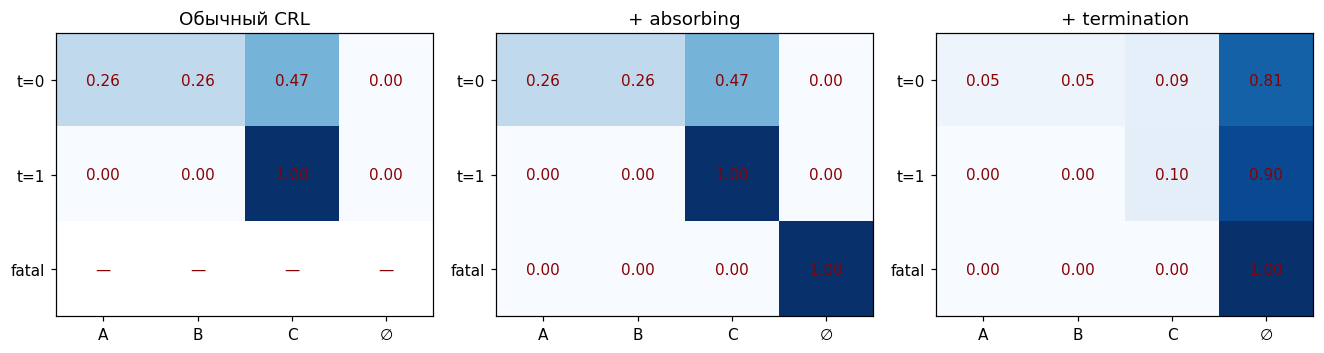

In [2]:
def make_targets(future_labels, terminated, gamma=0.95, gamma_term=0.90,
                 absorbing=True, rb=True, k_max=32, rng=None):
    """Одна строка на действие. Последняя строка при смерти — поглощение.

    future_labels[t] описывает s_(t+1), либо нулевой вектор при смерти.
    Возвращаем распределения и маску допустимых anchor (s_t, a_t).
    """
    labels = np.asarray(future_labels, dtype=np.float64)
    T, G = labels.shape
    assert 0 < gamma < 1 and 0 <= gamma_term < 1 and k_max >= 1
    rng = np.random.default_rng(0) if rng is None else rng
    targets = np.zeros((T, G + int(absorbing)))
    valid = np.ones(T, dtype=bool)
    alive_end = T - int(terminated)  # fatal next observation не является живой
    for t in range(T):
        K = min(k_max, max(alive_end - t, 0))
        if K == 0:
            if absorbing:
                targets[t, -1] = 1.0
            else:
                valid[t] = False  # ровно та потеря сигнала, которую обсуждает статья
            continue
        weights = gamma ** np.arange(K, dtype=np.float64)
        weights /= weights.sum()
        if rb:
            y = weights @ labels[t:t + K]
        else:
            # Семантическую метку уже усреднили; здесь семплируется только offset.
            y = labels[t + rng.choice(K, p=weights)]
        mass = 1.0
        if absorbing and terminated:
            delta = alive_end - t
            mass = 1.0 - gamma_term ** delta
        targets[t, :G] = mass * y
        if absorbing:
            targets[t, -1] = max(0.0, 1.0 - targets[t, :G].sum())
        elif y.sum() == 0:
            valid[t] = False
    return targets.astype(np.float32), valid

# Небольшая траектория: две живые observation, затем смерть.
# Первое будущее выполняет две цели, второе — одну.
example = np.array([[0.5, 0.5, 0.0], [0.0, 0.0, 1.0], [0.0, 0.0, 0.0]])
example_modes = {
    "Обычный CRL": dict(absorbing=False, gamma_term=0.0),
    "+ absorbing": dict(absorbing=True, gamma_term=0.0),
    "+ termination": dict(absorbing=True, gamma_term=0.9),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3), constrained_layout=True)
for ax, (name, args) in zip(axes, example_modes.items()):
    y, valid = make_targets(example, True, gamma=0.9, **args)
    plot_y = np.c_[y, np.zeros(3)] if y.shape[1] == 3 else y
    plot_y[~valid] = np.nan
    ax.imshow(plot_y, vmin=0, vmax=1, cmap="Blues")
    ax.set(xticks=range(4), xticklabels=["A", "B", "C", "∅"],
           yticks=range(3), yticklabels=["t=0", "t=1", "fatal"], title=name)
    for i in range(3):
        for j in range(4):
            ax.text(j, i, "—" if not valid[i] else f"{plot_y[i,j]:.2f}",
                    ha="center", va="center", color="darkred")
plt.show()

Пустая строка слева — не отрицательный пример, а **полное отсутствие градиента**. В средней панели последний action уже штрафуется, но предыдущий всё ещё отдаёт 100% массы C. Справа часть массы переносится в ∅ заранее.

Проверим именно смысловые инварианты: нормировку, смертельное действие, отсутствие штрафа у time-limit, равенство точной геометрической сумме при полном будущем, влияние `k_max` и нулевых меток.

Проверки меток: 7 смысловых инвариантов выполнены.


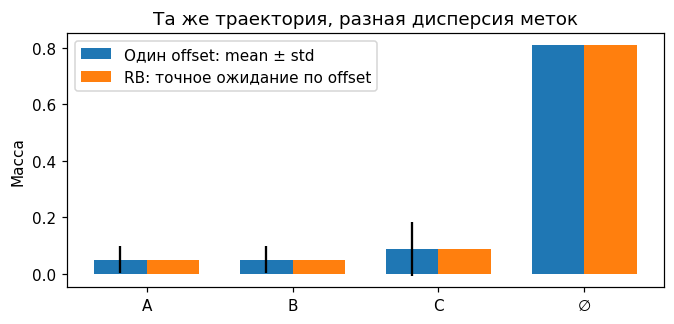

Максимальное отклонение MC-среднего: 0.00113


In [3]:
def check_targets():
    y, valid = make_targets(example, True, gamma=0.9, gamma_term=0.9, k_max=20)
    np.testing.assert_allclose(y.sum(1), 1, atol=1e-6)
    np.testing.assert_allclose(y[-1], [0, 0, 0, 1])
    np.testing.assert_allclose(y[0, :3], 0.1 * example[0] + 0.09 * example[1], atol=1e-6)
    np.testing.assert_allclose(y[:, -1], [0.9**2, 0.9, 1], atol=1e-6)
    timeout, _ = make_targets(example[:2], False, gamma_term=0.9)
    np.testing.assert_allclose(timeout[:, -1], 0, atol=1e-6)
    standard, mask = make_targets(example, True, absorbing=False)
    assert mask.tolist() == [True, True, False]
    capped, _ = make_targets(example, True, gamma_term=0.9, k_max=1)
    np.testing.assert_allclose(capped[0, :3], (1-0.9**2) * example[0], atol=1e-6)
    empty, _ = make_targets(np.zeros((1, 3)), False)
    np.testing.assert_allclose(empty, [[0, 0, 0, 1]])
    # После поглощения добавленные нулевые будущие не создают массу на целях.
    assert valid.all() and (y >= 0).all()
    print("Проверки меток: 7 смысловых инвариантов выполнены.")

check_targets()

# Rao–Blackwell: сравниваем одинаковую фиксированную траекторию, меняем лишь offset.
rng = np.random.default_rng(17)
samples = np.array([make_targets(example, True, gamma=0.9, gamma_term=0.9,
                    rb=False, rng=rng)[0][0] for _ in range(4000)])
exact, _ = make_targets(example, True, gamma=0.9, gamma_term=0.9)
fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(4)
ax.bar(x-.18, samples.mean(0), .36, yerr=samples.std(0), label="Один offset: mean ± std")
ax.bar(x+.18, exact[0], .36, label="RB: точное ожидание по offset")
ax.set(xticks=x, xticklabels=["A", "B", "C", "∅"], ylabel="Масса", title="Та же траектория, разная дисперсия меток")
ax.legend(); plt.show()
print("Максимальное отклонение MC-среднего:", round(float(abs(samples.mean(0)-exact[0]).max()), 5))

## 4. Среды: Grid и MiniCraft

**Grid**: навигация вокруг стены, без смертей. Цели — клетки и две перекрывающиеся области. Это проверка базового CRL.

**MiniCraft**: лабиринт, мгновенная смерть в лаве `L`, потеря здоровья на горячей клетке `H`, ключ `K`, дверь `D`, дерево `W`, верстак `T`, выход `E`. На `K/W/T` нужно действие **«взаимодействовать»**; для инструмента нужна древесина, она расходуется. Через дверь можно пройти только с ключом. Семантическая сложная цель: прийти на выход с инструментом. На старте `S` можно восстановить здоровье взаимодействием. На выходе эпизод продолжается.

Состояние — `(x, y, key, wood, tool, hp)`. Полная наблюдаемость, фиксированная карта и маленькое пространство состояний — осознанные упрощения. MiniCraft сложнее Grid, но не заменяет Craftax.

Мы перечисляем достижимые состояния и заранее считаем детерминированные переходы, чтобы учить быстро. **Обучение получает только посещённые траектории**, а не таблицу оптимальных действий. Перечисление графа нужно симулятору, диагностике достижимости и отдельному oracle для сравнения.

In [4]:
class World:
    actions = ("вверх", "вниз", "влево", "вправо", "взаимодействовать", "ждать")
    moves = ((0,-1), (0,1), (-1,0), (1,0))

    def __init__(self, hard=False):
        self.hard = hard
        self.name = "MiniCraft" if hard else "Grid"
        lines = (["#########", "#S..L..E#", "#.#LL#D##", "#K...#..#",
                  "#..H.TW.#", "#.......#", "#########"] if hard else
                 ["#######", "#S....#", "#..#..#", "#.....#", "#######"])
        self.map = np.array([list(row) for row in lines])
        self.height, self.width = self.map.shape
        sy, sx = np.argwhere(self.map == "S")[0]
        self.initial = (int(sx), int(sy), 0, 0, 0, 3 if hard else 1)
        # BFS не включает поглощающее состояние в набор живых состояний.
        self.states = [self.initial]
        self.index = {self.initial: 0}
        q = deque([self.initial])
        while q:
            s = q.popleft()
            for a in range(6):
                nxt, dead = self.transition(s, a)
                if not dead and nxt not in self.index:
                    self.index[nxt] = len(self.states)
                    self.states.append(nxt)
                    q.append(nxt)
        self.n_states, self.n_actions = len(self.states), 6
        self.next = np.zeros((self.n_states, 6), dtype=np.int64)
        self.dead = np.zeros((self.n_states, 6), dtype=bool)
        for i, s in enumerate(self.states):
            for a in range(6):
                nxt, dead = self.transition(s, a)
                self.dead[i,a] = dead
                self.next[i,a] = -1 if dead else self.index[nxt]
        self.cells = sorted({s[:2] for s in self.states}, key=lambda p:(p[1], p[0]))
        self.goal_names = [f"клетка ({x},{y})" for x,y in self.cells]
        self.goal_names += ["левая область", "правая область"]
        if hard:
            self.goal_names += ["есть ключ", "есть древесина", "есть инструмент",
                                "рядом с верстаком", "выход с инструментом", "здоровье = 1"]
        self.G = len(self.goal_names)
        self.predicates = np.array([self.goals(s) for s in self.states], dtype=np.float32)
        count = self.predicates.sum(1, keepdims=True)
        self.labels = self.predicates / np.maximum(count, 1)
        assert (count > 0).all() and self.predicates.max(0).min() == 1
        # One-hot положения + инвентарь и здоровье — вход PPO-сети.
        eye = np.eye(len(self.cells), dtype=np.float32)
        cell_index = {p:i for i,p in enumerate(self.cells)}
        self.features = np.array([np.r_[eye[cell_index[s[:2]]], s[2:5], s[5]/3]
                                  for s in self.states], dtype=np.float32)

    def transition(self, s, a):
        x,y,key,wood,tool,hp = s
        if a < 4:
            dx,dy = self.moves[a]
            nx,ny = x+dx,y+dy
            c = self.map[ny,nx]
            if c != "#" and not (c == "D" and not key):
                x,y = nx,ny
                if c == "L":
                    return None, True
                if c == "H":
                    hp -= 1
                    if hp <= 0:
                        return None, True
        elif a == 4:
            c = self.map[y,x]
            if c == "K": key = 1
            if c == "W": wood = 1
            if c == "T" and wood: tool,wood = 1,0
            if c == "S": hp = 3 if self.hard else 1
        return (x,y,key,wood,tool,hp), False

    def goals(self, s):
        x,y,key,wood,tool,hp = s
        vals = [float((x,y)==p) for p in self.cells]
        vals += [float(x <= self.width//2), float(x >= self.width//2)]
        if self.hard:
            ty,tx = np.argwhere(self.map=="T")[0]
            vals += [key, wood, tool, float(abs(x-tx)+abs(y-ty)<=1),
                     float(self.map[y,x]=="E" and tool), float(hp==1)]
        return np.array(vals, dtype=np.float32)

    def goal_id(self, name): return self.goal_names.index(name)

    def shortest_path(self, goal, start=0):
        """Oracle только для диагностики; его действия не идут в обучение."""
        q = deque([(start, [])]); visited = {start}
        while q:
            s, path = q.popleft()
            if self.predicates[s,goal]: return path
            for a in range(6):
                n = self.next[s,a]
                if n >= 0 and n not in visited:
                    visited.add(n); q.append((int(n), path+[a]))
        return None

worlds = {"Grid": World(), "MiniCraft": World(hard=True)}
for w in worlds.values():
    d = [len(w.shortest_path(g)) for g in range(w.G)]
    print(f"{w.name}: {w.n_states} живых состояний, {w.G} целей; "
          f"кратчайшее решение самой дальней цели: {max(d)} действий")

Grid: 14 живых состояний, 16 целей; кратчайшее решение самой дальней цели: 6 действий
MiniCraft: 616 живых состояний, 36 целей; кратчайшее решение самой дальней цели: 17 действий


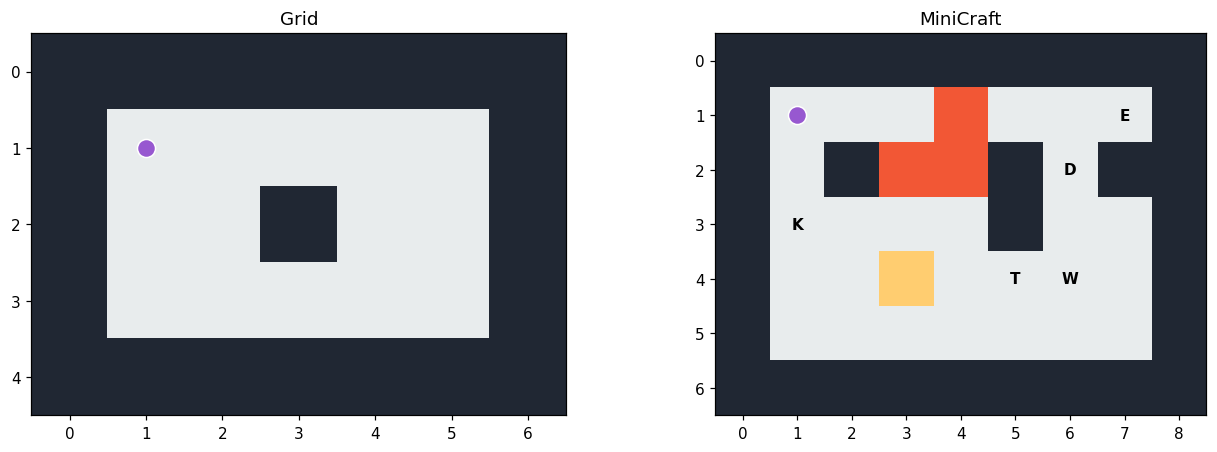

Механика смерти, двери, крафта и достижимость сложной цели проверены.


In [5]:
COLORS = ["#202733", "#e8eced", "#f25735", "#ffcd70"]

def draw_world(w, ax=None, state=0, path=None, goal=None, title=None):
    if ax is None: _, ax = plt.subplots(figsize=(6,4))
    tiles = np.ones(w.map.shape, dtype=int)
    tiles[w.map=="#"] = 0; tiles[w.map=="L"] = 2; tiles[w.map=="H"] = 3
    ax.imshow(tiles, cmap=ListedColormap(COLORS), vmin=0, vmax=3)
    for y in range(w.height):
        for x in range(w.width):
            c = w.map[y,x]
            if c not in "#.LH": ax.text(x,y,c,ha="center",va="center",fontweight="bold")
    if goal is not None:
        # Срез карты при фиксированном инвентаре, а не все варианты состояния сразу.
        base = w.states[state]
        for x,y in w.cells:
            s = (x,y,*base[2:])
            if w.goals(s)[goal]:
                ax.scatter(x,y,s=200,marker="s",facecolors="none",edgecolors="#339966",linewidths=2)
    if path:
        pts = np.array([w.states[s][:2] for s in path if s >= 0])
        ax.plot(pts[:,0],pts[:,1],"o-",color="#4378cc",alpha=.7,markersize=3)
    x,y,*_ = w.states[state]
    ax.scatter(x,y,s=140,c="#9758d0",edgecolors="white",zorder=5)
    ax.set(xticks=range(w.width),yticks=range(w.height),title=title or w.name)
    ax.set_xlim(-.5,w.width-.5); ax.set_ylim(w.height-.5,-.5)
    return ax

fig, axes = plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,w in zip(axes,worlds.values()): draw_world(w,ax)
plt.show()

hard = worlds["MiniCraft"]
# Явная проверка механики среды: смерть, крафт, дверь, дальняя цель.
assert hard.transition((3,1,0,0,0,3),3)[1]  # справа лава
assert hard.transition((3,3,0,0,0,1),1)[1]  # горячая клетка при 1 hp
assert hard.transition((6,3,0,0,0,3),0)[0][:2] == (6,3)  # дверь закрыта
assert hard.transition((5,4,0,1,0,3),4)[0][3:5] == (0,1)  # wood -> tool
assert len(hard.shortest_path(hard.goal_id("выход с инструментом"))) > 10
print("Механика смерти, двери, крафта и достижимость сложной цели проверены.")

## 5. Критик: что хранится внутри сети?

На каждую пару $(s,a)$ есть вектор $\phi(s,a)\in\mathbb R^d$, на каждую цель — $\psi(g)\in\mathbb R^d$. Одна матрица умножения получает логиты всех целей. Для поглощения не обучаем ни эмбеддинг, ни bias: дописываем ноль.

С поглощающим классом оптимальный логит — $f_g=\log(p_g/p_\varnothing)$. Поэтому ни логит, ни его sigmoid не являются вероятностью цели. Даже ранжирование действий по $f_g$ может отличаться от ранжирования по $p_g$: знаменатель $p_\varnothing$ меняется с действием. Статья выбирает **argmax логита $f$**; ниже по умолчанию делаем так же. В инспекторе покажем обе шкалы, а `action_score="probability"` позволяет исследовать другой вариант (это уже отклонение от статьи).

Критик не получает командуемую цель как вход энкодера состояния: он оценивает все цели сразу. Поскольку продолжение траектории зависит от поведения агента и его команды, выученная занятость относится к смеси continuation policies из данных, а не к точному $Q^{\pi(\cdot|g)}$ для каждой команды. Политика и распределение данных меняются совместно.

In [6]:
@dataclass
class Config:
    seed: int = 0
    gamma: float = 0.95
    gamma_term: float = 0.90
    k_max: int = 32
    absorbing: bool = True
    rb: bool = True
    dim: int = 24
    lr: float = 0.02
    rounds: int = 35
    episodes_per_round: int = 20
    horizon: int = 64
    updates: int = 28
    batch_size: int = 256
    epsilon_start: float = 1.0
    epsilon_end: float = 0.20
    replay_size: int = 25_000
    action_score: str = "logit"

# Это главный пульт: изменяйте копии конфигурации, не внутренние функции.
BASE = Config()
SEEDS = [0, 1]  # Для серьёзного вывода используйте хотя бы 5–10 независимых seed.
PPO_ITERATIONS = 55

class CRLCritic(nn.Module):
    def __init__(self, w, cfg):
        super().__init__()
        self.A, self.G, self.d = w.n_actions, w.G, cfg.dim
        self.absorbing = cfg.absorbing
        self.phi = nn.Embedding(w.n_states, self.A * self.d)
        self.psi = nn.Embedding(self.G, self.d)
        nn.init.normal_(self.phi.weight, std=0.1)
        nn.init.normal_(self.psi.weight, std=0.2)

    def forward(self, state_ids):
        sa = self.phi(state_ids).reshape(-1,self.A,self.d)
        return sa @ self.psi.weight.T

    def class_logits(self, state_ids):
        logits = self(state_ids)
        if self.absorbing:
            logits = torch.cat([logits, torch.zeros_like(logits[...,:1])],dim=-1)
        return logits

@torch.no_grad()
def critic_table(model, w, action_score="logit"):
    logits = model.class_logits(torch.arange(w.n_states))
    probs = logits.softmax(-1).numpy()
    scores = logits.numpy()[...,:w.G] if action_score=="logit" else probs[...,:w.G]
    return scores, probs

## 6. Сбор опыта и обучение

Собираем полные эпизоды до смерти или time-limit, а `k_max` ограничивает доступное будущее. После достижения команды выбираем новую цель из уже встречавшихся предикатов — небольшой curriculum, аналогичный статье. До встречи новых целей исследование идёт через ε-greedy.

Одна траектория переиспользуется для всех целей, но **не содержит oracle-действий**. Чтобы небольшому CPU-эксперименту хватало данных, добавлен replay buffer с готовыми метками. В статье используется rollout-based обучение; replay здесь — упрощение, создающее смесь старых continuation policies. При сильном устаревании старые метки могут мешать; уменьшите `replay_size` для проверки.

Контроль: evaluation выполняется без ε-исследования, по фиксированным целям, с исходного состояния, с горизонтом 64. Success = цель встретилась хотя бы раз (включая начальное состояние); death = умер за весь горизонт. Эти события могут произойти в одном эпизоде. Это разные метрики, а не две части единицы.

Оптимизатор в учебной версии — Adam; в статье для CRL используется RAdam. Learning rate, ёмкость и бюджет здесь выбраны для маленьких CPU-задач.

In [7]:
def collect_episode(w, scores, cfg, rng, epsilon, seen_goals):
    s = 0
    goal = int(rng.choice(sorted(seen_goals)))
    ids, acts, labels = [], [], []
    for _ in range(cfg.horizon):
        a = int(rng.integers(w.n_actions)) if rng.random()<epsilon else int(np.argmax(scores[s,:,goal]))
        ids.append(s); acts.append(a)
        n = int(w.next[s,a]); dead = bool(w.dead[s,a])
        labels.append(np.zeros(w.G) if dead else w.labels[n])
        if dead: break
        s = n
        seen_goals.update(np.flatnonzero(w.predicates[s]).tolist())
        if w.predicates[s,goal]:
            goal = int(rng.choice(sorted(seen_goals)))
    y, valid = make_targets(labels, dead, cfg.gamma, cfg.gamma_term,
                           cfg.absorbing, cfg.rb, cfg.k_max, rng)
    return np.array(ids)[valid], np.array(acts)[valid], y[valid], dead

@torch.no_grad()
def evaluate(w, policy, horizon=64, goals=None):
    goals = list(range(w.G)) if goals is None else list(goals)
    success, deaths, lengths = [], [], []
    for g in goals:
        s, dead, achieved, length = 0, False, bool(w.predicates[0,g]), 0
        for t in range(horizon):
            a = int(policy(s,g))
            n = int(w.next[s,a]); length = t+1
            if n < 0:
                dead = True; break
            s = n
            achieved |= bool(w.predicates[s,g])
        success.append(achieved); deaths.append(dead); lengths.append(length)
    return {"success":float(np.mean(success)), "death":float(np.mean(deaths)),
            "length":float(np.mean(lengths)), "by_goal":np.array(success,dtype=float)}


def train_crl(w, cfg, verbose=False):
    seed_all(cfg.seed); rng = np.random.default_rng(cfg.seed)
    model = CRLCritic(w,cfg).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(),lr=cfg.lr)
    seen = set(np.flatnonzero(w.predicates[0]).tolist())
    replay_s = np.empty(0,dtype=np.int64); replay_a = replay_s.copy()
    replay_y = np.empty((0,w.G+int(cfg.absorbing)),dtype=np.float32)
    history, steps, visited = [], 0, set()
    training_death = np.nan
    for iteration in range(cfg.rounds+1):
        scores, _ = critic_table(model,w,cfg.action_score)
        if iteration % 5 == 0 or iteration == cfg.rounds:
            ev = evaluate(w,lambda s,g: scores[s,:,g].argmax(),cfg.horizon)
            history.append(dict(step=steps, iteration=iteration, success=ev["success"],
                                death=ev["death"], goals=len(seen)/w.G, train_death=training_death))
        if iteration == cfg.rounds: break
        fraction = iteration / max(cfg.rounds-1,1)
        epsilon = cfg.epsilon_start + fraction*(cfg.epsilon_end-cfg.epsilon_start)
        ss, aa, yy = [], [], []
        episode_deaths = []
        for _ in range(cfg.episodes_per_round):
            s,a,y,dead = collect_episode(w,scores,cfg,rng,epsilon,seen)
            ss.append(s); aa.append(a); yy.append(y); episode_deaths.append(dead)
            steps += len(s) + int(dead and not cfg.absorbing)
            visited.update(s.tolist())
        training_death = float(np.mean(episode_deaths))
        replay_s = np.concatenate([replay_s,*ss])[-cfg.replay_size:]
        replay_a = np.concatenate([replay_a,*aa])[-cfg.replay_size:]
        replay_y = np.concatenate([replay_y,*yy])[-cfg.replay_size:]
        s_tensor = torch.from_numpy(replay_s); a_tensor = torch.from_numpy(replay_a)
        y_tensor = torch.from_numpy(replay_y)
        for _ in range(cfg.updates):
            idx = torch.from_numpy(rng.integers(len(replay_s),size=cfg.batch_size))
            logp = model.class_logits(s_tensor[idx])[torch.arange(cfg.batch_size),a_tensor[idx]].log_softmax(-1)
            loss = -(y_tensor[idx]*logp).sum(-1).mean()
            optimizer.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
        assert torch.isfinite(loss)
        if verbose and (iteration+1)%10==0:
            print(w.name, iteration+1, "loss", round(loss.item(),3), "открыто целей",len(seen))
    scores, _ = critic_table(model,w,cfg.action_score)
    final = evaluate(w,lambda s,g: scores[s,:,g].argmax(),cfg.horizon)
    return dict(model=model, cfg=cfg, history=history, final=final,
                seen=seen, state_coverage=len(visited)/w.n_states, steps=steps)

## 7. Абляции: что дают отдельные изменения?

Сравниваем три режима: обычный CRL без ∅, добавление ∅ только для последнего действия и ∅ с termination discount. Во всех трёх включён RB, чтобы не смешивать эффект дисперсии с эффектом смерти. В Grid хватит первого и третьего.

Используются одинаковые seeds и гиперпараметры; после первых разных действий траектории уже различаются. Поэтому это сравнение **целых алгоритмов**, а не контролируемая оценка смещения на одних данных. Контроль на одной траектории был в разделе 3. Бюджет — одинаковое число раундов и эпизодов; число шагов может различаться из-за смертей и показано на оси X.

Ожидаем, что ∅ уменьшит часть смертей. Рост success не гарантирован: метод оптимизирует другую величину, а дальняя цель может вообще не встретиться. Два seed дают лишь учебную диагностику, не статистически надёжный результат. Честно смотрите и на `goals`, и на покрытие состояний.

In [8]:
MODES = {
    "CRL": dict(absorbing=False, gamma_term=0.0),
    "+ ∅": dict(absorbing=True, gamma_term=0.0),
    "+ ∅ + termination": dict(absorbing=True, gamma_term=BASE.gamma_term),
}
results = {}
started = time.time()
for name,w in worlds.items():
    names = ["CRL", "+ ∅ + termination"] if name=="Grid" else list(MODES)
    for mode in names:
        runs=[]
        for seed in SEEDS:
            cfg = replace(BASE,seed=seed,**MODES[mode])
            run = train_crl(w,cfg)
            runs.append(run)
            print(f"{name:10s} | {mode:20s} | seed={seed} | "
                  f"success={run['final']['success']:.2f} | death={run['final']['death']:.2f} | "
                  f"цели={len(run['seen'])}/{w.G} | шаги={run['steps']}", flush=True)
        results[(name,mode)] = runs
print(f"Обучение заняло {(time.time()-started)/60:.1f} мин.")

Grid       | CRL                  | seed=0 | success=0.94 | death=0.00 | цели=16/16 | шаги=44800


Grid       | CRL                  | seed=1 | success=0.88 | death=0.00 | цели=16/16 | шаги=44800


Grid       | + ∅ + termination    | seed=0 | success=0.62 | death=0.00 | цели=16/16 | шаги=44800


Grid       | + ∅ + termination    | seed=1 | success=0.50 | death=0.00 | цели=16/16 | шаги=44800


MiniCraft  | CRL                  | seed=0 | success=0.50 | death=0.00 | цели=35/36 | шаги=28181


...

MiniCraft  | + ∅                  | seed=0 | success=0.28 | death=0.00 | цели=35/36 | шаги=33647


MiniCraft  | + ∅                  | seed=1 | success=0.11 | death=0.00 | цели=34/36 | шаги=33619


MiniCraft  | + ∅ + termination    | seed=0 | success=0.08 | death=0.00 | цели=36/36 | шаги=37664


MiniCraft  | + ∅ + termination    | seed=1 | success=0.19 | death=0.00 | цели=35/36 | шаги=37472


Обучение заняло 0.5 мин.


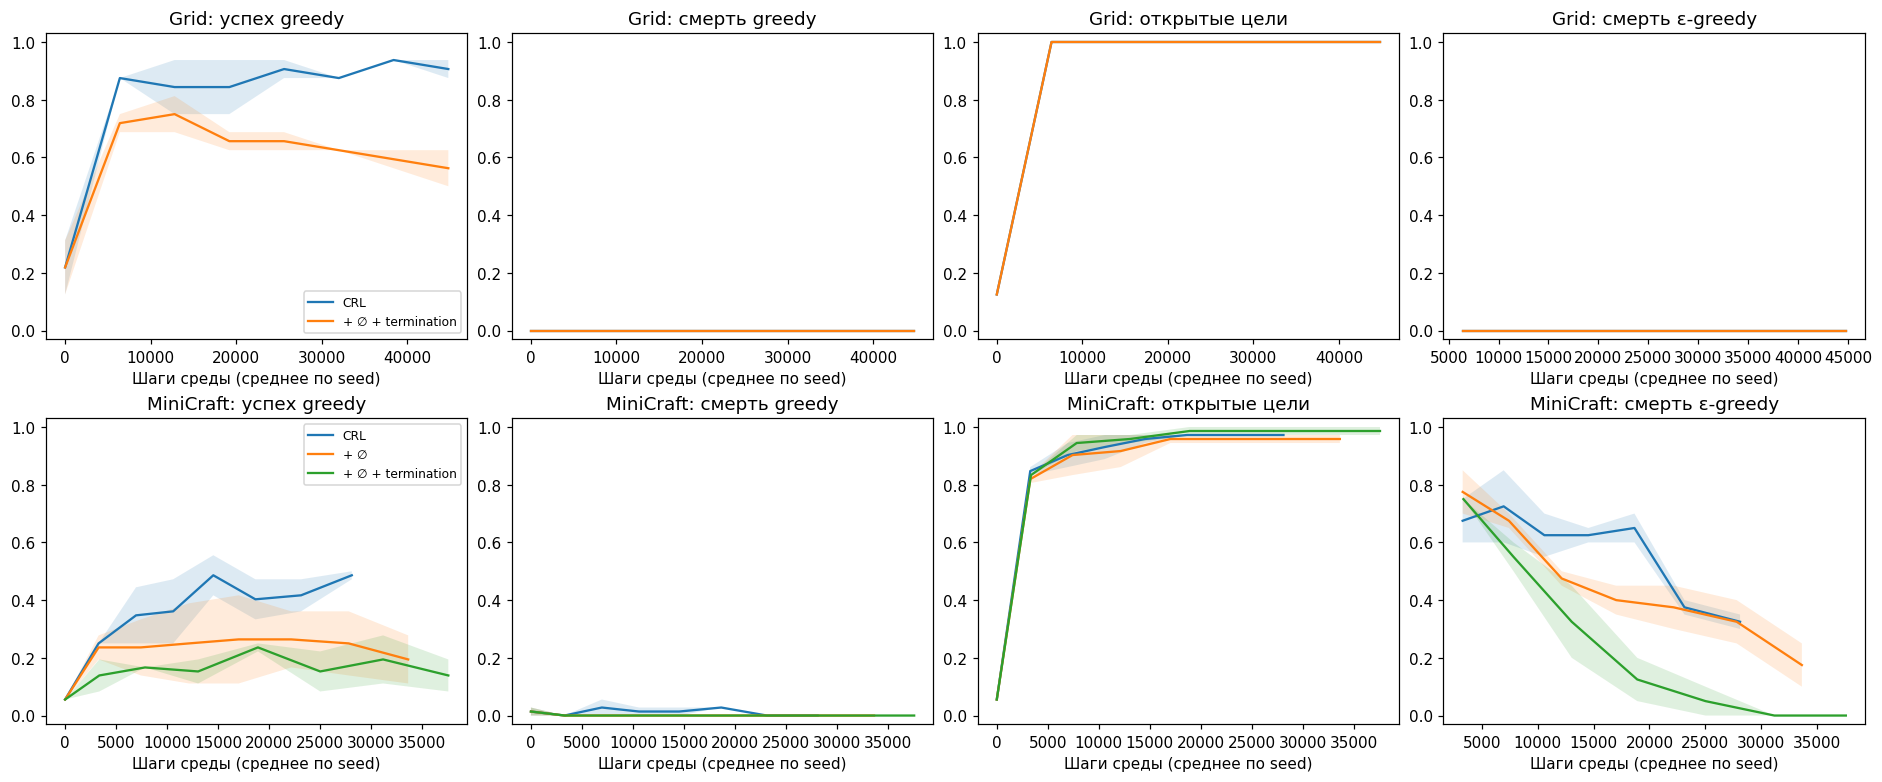

| Среда | Метод | Success, mean ± std | Death, mean ± std | Покрытие состояний |
|:--|:--|--:|--:|--:|
| Grid | CRL | 0.91 ± 0.03 | 0.00 ± 0.00 | 100.0% |
| Grid | + ∅ + termination | 0.56 ± 0.06 | 0.00 ± 0.00 | 100.0% |
| MiniCraft | CRL | 0.49 ± 0.01 | 0.00 ± 0.00 | 43.1% |
| MiniCraft | + ∅ | 0.19 ± 0.08 | 0.00 ± 0.00 | 36.4% |
| MiniCraft | + ∅ + termination | 0.14 ± 0.06 | 0.00 ± 0.00 | 39.4% |

In [9]:
fig, axes = plt.subplots(2,4,figsize=(17,7),constrained_layout=True)
for row,(name,w) in enumerate(worlds.items()):
    for (env_name,mode),runs in results.items():
        if env_name!=name: continue
        for col,key in enumerate(["success","death","goals","train_death"]):
            x=np.mean([[h["step"] for h in r["history"]] for r in runs],axis=0)
            values=np.array([[h[key] for h in r["history"]] for r in runs])
            mean,std=values.mean(0),values.std(0)
            axes[row,col].plot(x,mean,label=mode)
            axes[row,col].fill_between(x,np.clip(mean-std,0,1),np.clip(mean+std,0,1),alpha=.15)
            axes[row,col].set(xlabel="Шаги среды (среднее по seed)",ylim=(-.03,1.03),
                              title=f"{name}: {['успех greedy','смерть greedy','открытые цели','смерть ε-greedy'][col]}")
    axes[row,0].legend(fontsize=8)
plt.show()

rows=["| Среда | Метод | Success, mean ± std | Death, mean ± std | Покрытие состояний |",
      "|:--|:--|--:|--:|--:|"]
for (name,mode),runs in results.items():
    s=np.array([r["final"]["success"] for r in runs]); d=np.array([r["final"]["death"] for r in runs])
    coverage=np.mean([r["state_coverage"] for r in runs])
    rows.append(f"| {name} | {mode} | {s.mean():.2f} ± {s.std():.2f} | {d.mean():.2f} ± {d.std():.2f} | {coverage:.1%} |")
display(Markdown(chr(10).join(rows)))

**Как читать сохранённый прогон.** В этой конфигурации базовый CRL лучше решает навигационные цели, а вариант с termination discount заметно уменьшает смерти **исследующей ε-greedy политики**, но часто останавливается в безопасном месте. У всех методов финальная greedy death мала — сама по себе эта метрика не доказывает, что агент научился действовать полезно. Низкое покрытие состояний MiniCraft и различие occupancy/first-hit success также ограничивают результат. Это учебный пример, где улучшение корректности targets не гарантирует улучшения всей обучаемой системы. Ниже отдельно исследуем выбор по логиту и по вероятности. После изменения параметров заново проверяйте выводы по своим графикам.

### Посмотрим на конкретные цели и поведение

Первые столбцы — навигационные цели, последние — семантические. Низкая средняя success может скрывать полное освоение простых задач и провал крафта. Oracle ниже использует полный граф среды и **не является обученным агентом**: он показывает, что сложная цель существует и достижима. Наличие пути у oracle не доказывает, что RL должен найти его при текущем бюджете.

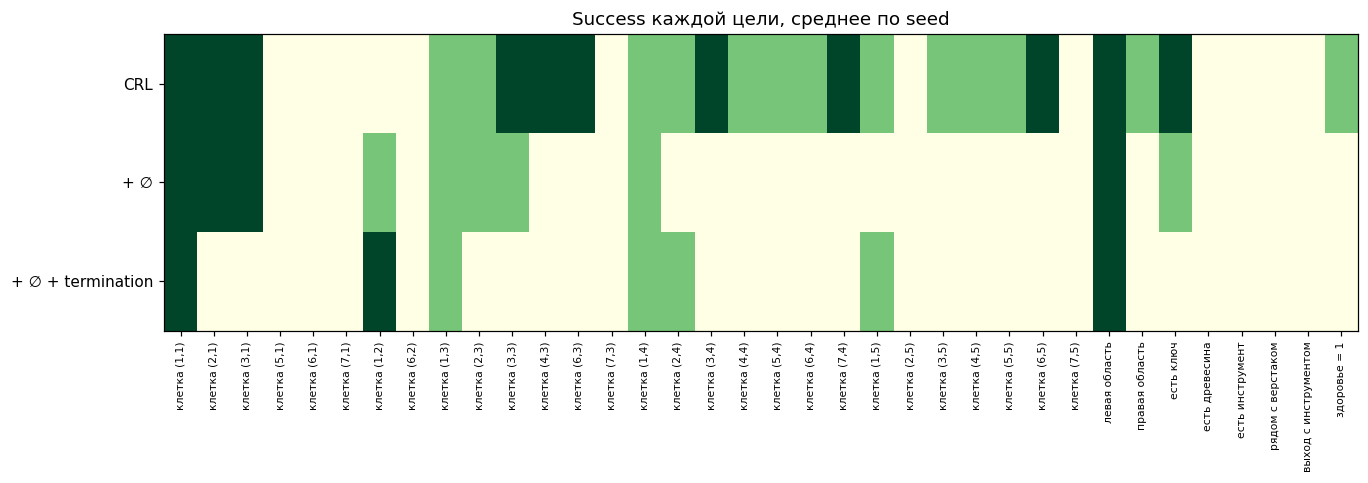

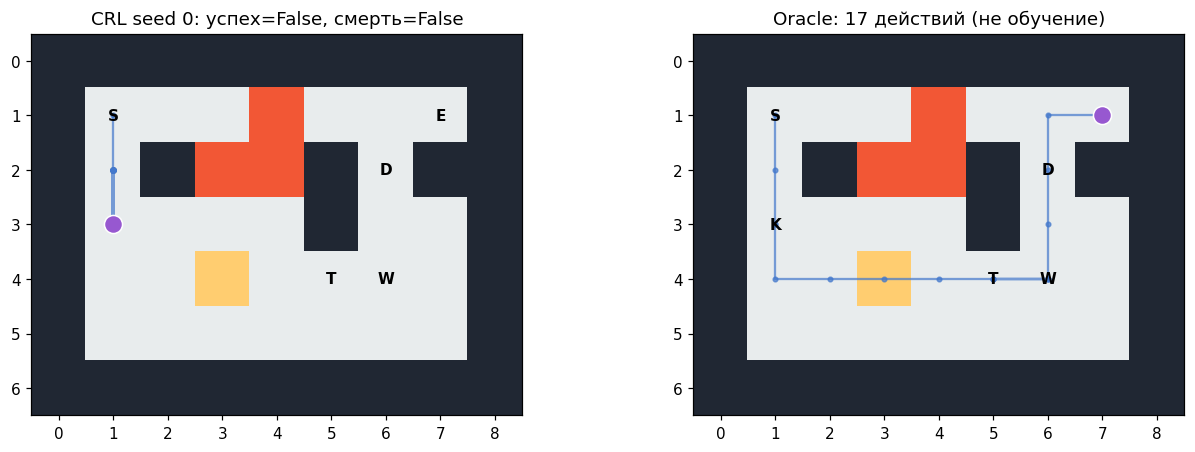

In [10]:
hard = worlds["MiniCraft"]
fig,ax=plt.subplots(figsize=(14,3.5))
mode_names=list(MODES)
by_goal=np.array([np.mean([r["final"]["by_goal"] for r in results[("MiniCraft",m)]],axis=0) for m in mode_names])
ax.imshow(by_goal,aspect="auto",vmin=0,vmax=1,cmap="YlGn")
ax.set(yticks=range(3),yticklabels=mode_names,xticks=range(hard.G),
       xticklabels=hard.goal_names,title="Success каждой цели, среднее по seed")
plt.setp(ax.get_xticklabels(),rotation=90,fontsize=7); plt.show()


def rollout_path(w, policy, goal, horizon=64, stop_on_success=True):
    s=0; path=[s]; actions=[]; death=False
    for _ in range(horizon):
        if stop_on_success and w.predicates[s,goal]: break
        a=int(policy(s,goal)); actions.append(a); n=int(w.next[s,a])
        if n<0: death=True; break
        s=n; path.append(s)
    return path,actions,death,bool(w.predicates[s,goal])

# Берём seed 0 заранее, не отбираем самый успешный seed задним числом.
teacher_run=results[("MiniCraft","+ ∅ + termination")][0]
teacher=teacher_run["model"]
teacher_scores,teacher_probs=critic_table(teacher,hard,BASE.action_score)
challenge_goal=hard.goal_id("выход с инструментом")
oracle_actions=hard.shortest_path(challenge_goal)
oracle_path=[0]
for a in oracle_actions: oracle_path.append(int(hard.next[oracle_path[-1],a]))
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
path,actions,died,success=rollout_path(hard,lambda s,g: teacher_scores[s,:,g].argmax(),challenge_goal)
draw_world(hard,axes[0],state=path[-1],path=path,
           title=f"CRL seed 0: успех={success}, смерть={died}")
draw_world(hard,axes[1],state=oracle_path[-1],path=oracle_path,
           title=f"Oracle: {len(oracle_actions)} действий (не обучение)")
plt.show()

## 8. Заглянем внутрь критика: действия, вероятности и карта ∅

Выберите клетку около лавы. У фатального действия ожидается высокая остаточная масса. У безопасного действия $p_\varnothing$ тоже может быть большой: оно учитывает **всё последующее будущее**, а не только немедленную смерть. При `gamma_term != gamma` это ещё и изменённая целевая масса.

Карта ниже — срез при фиксированном инвентаре и здоровье. Смешивать состояния с разными `key/tool/hp` в одной клетке нельзя: это разные состояния MDP.

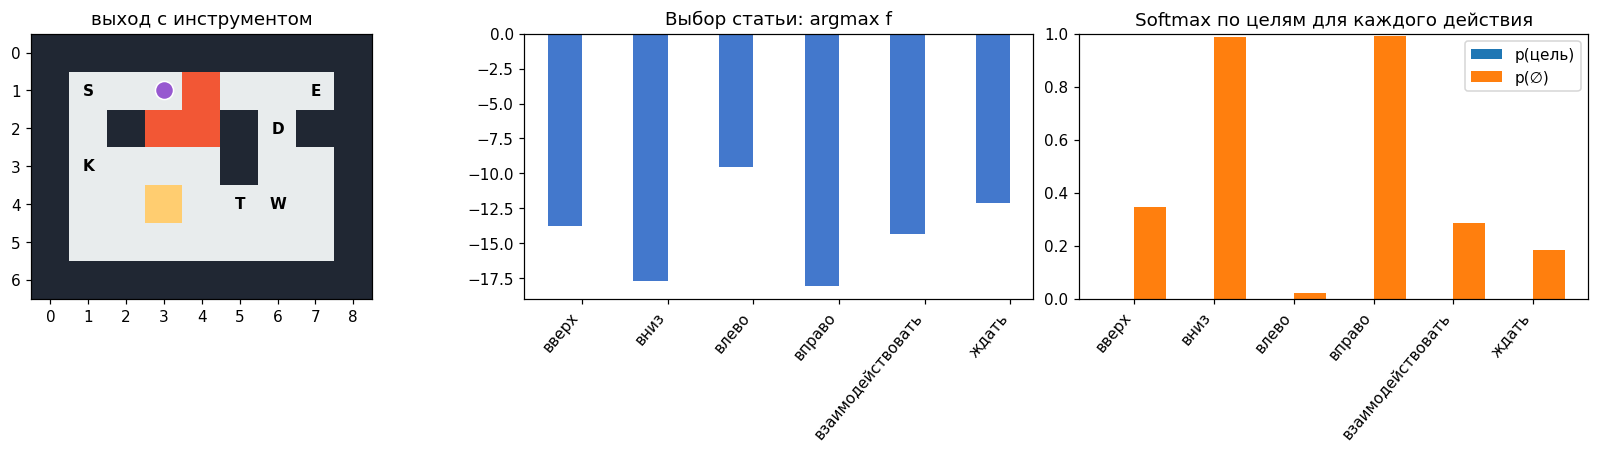

Состояние (x,y,key,wood,tool,hp): (3, 1, 0, 0, 0, 3)
argmax f: влево | argmax p(цель): влево


In [11]:
def inspect_critic(w, model, state, goal):
    scores, probs=critic_table(model,w)
    fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
    draw_world(w,axes[0],state=state,goal=goal,title=w.goal_names[goal])
    x=np.arange(w.n_actions)
    axes[1].bar(x-.2,scores[state,:,goal],.4,color="#4378cc",label="Логит f")
    axes[1].set(xticks=x,xticklabels=w.actions,title="Выбор статьи: argmax f")
    plt.setp(axes[1].get_xticklabels(),rotation=50,ha="right")
    axes[2].bar(x-.2,probs[state,:,goal],.4,label="p(цель)")
    if model.absorbing:
        axes[2].bar(x+.2,probs[state,:,-1],.4,label="p(∅)")
    axes[2].set(xticks=x,xticklabels=w.actions,ylim=(0,1),title="Softmax по целям для каждого действия")
    plt.setp(axes[2].get_xticklabels(),rotation=50,ha="right")
    axes[2].legend(); plt.show()
    print("Состояние (x,y,key,wood,tool,hp):",w.states[state])
    print("argmax f:",w.actions[scores[state,:,goal].argmax()],
          "| argmax p(цель):",w.actions[probs[state,:,goal].argmax()])

near_lava=hard.index[(3,1,0,0,0,3)]
inspect_critic(hard,teacher,near_lava,challenge_goal)

### Логит или вероятность: проверка на одном и том же критике

Меняем только правило выбора действия, сохраняя веса сети. Слева — $\arg\max_a f(s,a,g)$ из статьи, справа — $\arg\max_a p(g\mid s,a)$ как диагностический вариант. Это **не** два новых обучения и **не** доказательство превосходства другой политики в Craftax.

При маленьком $p_\varnothing$ даже небольшая вероятность цели даёт высокий $\log(p_g/p_\varnothing)$. Поэтому логит может предпочесть безопасное стояние на месте. Если такое произошло, не путайте отсутствие смертей с освоением целей. Наши маленькие карты, табличная ёмкость и бюджет отличаются от статьи: этот эксперимент исследует механизм, а не опровергает её результаты.

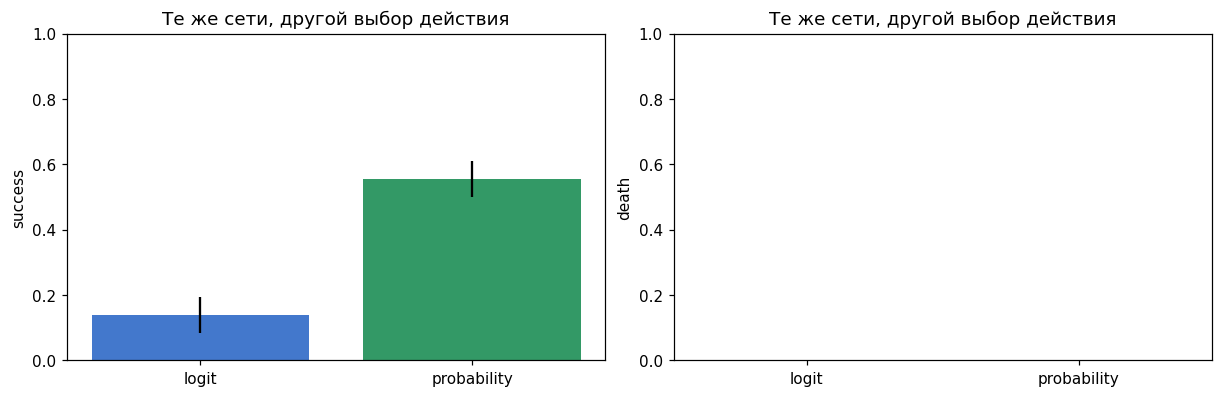

logit success = 0.139 death = 0.0
probability success = 0.556 death = 0.0


In [12]:
fig,axes=plt.subplots(1,2,figsize=(11,3.5),constrained_layout=True)
scoring_metrics={}
for scoring in ["logit","probability"]:
    metrics=[]
    for r in results[("MiniCraft","+ ∅ + termination")]:
        sc,_=critic_table(r["model"],hard,scoring)
        metrics.append(evaluate(hard,lambda s,g:sc[s,:,g].argmax()))
    scoring_metrics[scoring]=metrics
for ax,key in zip(axes,["success","death"]):
    names=list(scoring_metrics)
    values=np.array([[m[key] for m in scoring_metrics[n]] for n in names])
    ax.bar(names,values.mean(1),yerr=values.std(1),color=["#4378cc","#339966"])
    ax.set(ylim=(0,1),ylabel=key,title="Те же сети, другой выбор действия")
plt.show()
for scoring,metrics in scoring_metrics.items():
    print(scoring, "success =",round(np.mean([m["success"] for m in metrics]),3),
          "death =",round(np.mean([m["death"] for m in metrics]),3))

### Математический контроль: без SGD и без обучаемой политики

Чтобы отделить свойства меток от ошибок сети, зафиксируем **равномерную случайную continuation policy**. На конечном графе среды её истинную занятость можно найти итерациями:

$$Q_g(s,a)=\begin{cases}0,&\text{действие смертельно},\\
(1-\gamma)\ell_g(s')+\gamma V_g(s'),&\text{иначе},\end{cases}
\qquad V_g(s)=\frac1{|A|}\sum_a Q_g(s,a).$$

Это точная policy evaluation с точностью до численного допуска, а не дополнительный алгоритм обучения в основных экспериментах. Сравним её с усреднёнными метками **для одной фиксированной пары $(s,a)$**. `gamma_term=gamma`, окно почти бесконечное; ошибка time-limit порядка $\gamma^{256}$. При настоящей смерти скорректированные метки согласованы с этой занятостью. Обычные метки без ∅ условны на наблюдаемое живое будущее и распределяют всю массу по целям.

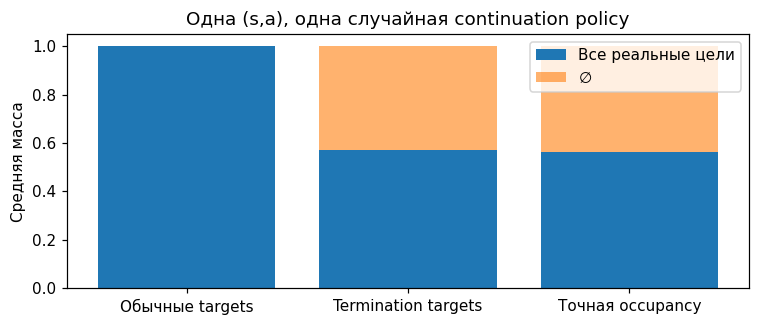

Policy evaluation: итераций 303
L1 ошибка MC-меток относительно exact: 0.01
Fatal action справа: true mass на целях = 0.0 | обычный CRL не получает для него ни одной валидной метки.


In [13]:
def exact_uniform_occupancy(w,gamma=.95,tol=1e-10):
    safe=np.maximum(w.next,0)
    live=(w.next>=0)[...,None]
    value=np.zeros((w.n_states,w.G),dtype=np.float64)
    for iteration in range(3000):
        q=((1-gamma)*w.labels[safe]+gamma*value[safe])*live
        nxt=q.mean(1)
        error=np.max(abs(nxt-value));value=nxt
        if error<tol: break
    else:
        raise RuntimeError("Policy evaluation не сошлась")
    q=((1-gamma)*w.labels[safe]+gamma*value[safe])*live
    assert np.max(q.sum(-1))<=1+1e-7 and np.max(abs(q[w.dead]),initial=0)==0
    return q,iteration+1

q_exact,n_iter=exact_uniform_occupancy(hard,BASE.gamma)
s0=near_lava;fixed_action=2  # первый action влево; далее равномерная π
rng=np.random.default_rng(31);raw=[];corrected=[]
for _ in range(2500):
    s=s0;future=[];dead=False
    for t in range(256):
        a=fixed_action if t==0 else int(rng.integers(hard.n_actions))
        n=int(hard.next[s,a])
        if n<0: dead=True;break
        future.append(hard.labels[n]);s=n
    K=len(future)
    if K:
        weights=BASE.gamma**np.arange(K);weights/=weights.sum()
        standard=weights@np.asarray(future)
        mass=(1-BASE.gamma**K) if dead else 1.0
        raw.append(standard);corrected.append(mass*standard)
    else:
        # Здесь первый action безопасен, но сохраняем правильную общую обработку.
        corrected.append(np.zeros(hard.G))
raw=np.mean(raw,0);corrected=np.mean(corrected,0);exact=q_exact[s0,fixed_action]
fig,ax=plt.subplots(figsize=(8,3))
x=np.arange(3);real_mass=np.array([raw.sum(),corrected.sum(),exact.sum()])
ax.bar(x,real_mass,label="Все реальные цели")
ax.bar(x,1-real_mass,bottom=real_mass,label="∅",alpha=.6)
ax.set(xticks=x,xticklabels=["Обычные targets","Termination targets","Точная occupancy"],
       ylim=(0,1.05),ylabel="Средняя масса",title="Одна (s,a), одна случайная continuation policy")
ax.legend();plt.show()
print("Policy evaluation: итераций",n_iter)
print("L1 ошибка MC-меток относительно exact:",round(float(abs(corrected-exact).sum()),4))
print("Fatal action справа: true mass на целях =",q_exact[s0,3].sum(),
      "| обычный CRL не получает для него ни одной валидной метки.")

## 9. Dual-CRL-PPO: отдельная политика учится у критика

PPO получает обычную награду $r_t=\mathbf1[P_g(s_{t+1})]$ для текущей команды. CRL по тем же данным учит **все** цели. Teacher даёт $a^*=\arg\max_a f(s,a,g)$, и к PPO добавляется:

$$L=L_{PPO}+c_V L_V-c_H H(\pi)+\beta_t\,\mathrm{CE}(\pi(\cdot|s,g),a^*).$$

Здесь $L_{PPO}=-\mathbb E[\min(r_t(\theta)A_t,\operatorname{clip}(r_t(\theta),1-\epsilon,1+\epsilon)A_t)]$, а $r_t(\theta)$ в этой формуле — **отношение вероятностей**, не награда. Advantage считаем GAE. $\beta_t$ линейно убывает до 0: ошибочный teacher не должен навсегда ограничивать student.

Ниже действительно запускается PPO: on-policy опыт, old log probabilities, GAE, clipped surrogate, value loss, entropy и несколько эпох. Это не замена PPO одним behavioral cloning.

**Честное сравнение.** PPO и Dual собирают одинаковое число эпизодов/итераций. Teacher Dual начинает **с нуля**, отдельно от критика предыдущего раздела, и обновляется на тех же траекториях student. У Dual дополнительные вычисления обучения teacher; одинаковые шаги среды не означают одинаковые FLOPs. Эпизоды собираются параллельно небольшим batch, поэтому доступный curriculum обновляется
между batch. Команда фиксирована внутри эпизода, награда повторяется, пока предикат выполнен. Это проще, чем scheduler статьи, и меняет постановку награды student. Для CRL-меток оба типа завершения по-прежнему различаются.

На малом бюджете Dual не обязан превосходить PPO: teacher тоже должен успеть научиться. Для отладки можно включить `warm_teacher=True`, но это добавит предобучение и сделает сравнение по полному бюджету неравным; по умолчанию оно выключено.

In [14]:
class ActorCritic(nn.Module):
    def __init__(self,w):
        super().__init__()
        self.goal=nn.Embedding(w.G,16)
        self.body=nn.Sequential(nn.Linear(w.features.shape[1]+16,96),nn.Tanh(),
                                nn.Linear(96,96),nn.Tanh())
        self.actor=nn.Linear(96,w.n_actions)
        self.value=nn.Linear(96,1)
        self.register_buffer("observations",torch.tensor(w.features))
        nn.init.orthogonal_(self.actor.weight,gain=0.01)
        nn.init.zeros_(self.actor.bias)

    def forward(self,s,g):
        z=self.body(torch.cat([self.observations[s],self.goal(g)],dim=-1))
        return Categorical(logits=self.actor(z)),self.value(z).squeeze(-1)


def gae(rewards,values,next_values,terminated,gamma=.95,lam=.95):
    """Один rollout одного эпизода: time-limit bootstrap остаётся, смерть обнуляет его."""
    advantage=np.zeros(len(rewards),dtype=np.float32); tail=0.0
    for t in reversed(range(len(rewards))):
        mask=1.0-float(terminated[t])
        delta=rewards[t]+gamma*mask*next_values[t]-values[t]
        tail=delta+gamma*lam*mask*tail
        advantage[t]=tail
    return advantage,advantage+np.asarray(values,dtype=np.float32)

# Проверка bootstrap: reward=0, V=2, V_next=3.
adv_death,_=gae([0],[2],[3],[True])
adv_limit,_=gae([0],[2],[3],[False])
np.testing.assert_allclose(adv_death,[-2])
np.testing.assert_allclose(adv_limit,[.95*3-2],atol=1e-6)


def collect_ppo_batch(w,agent,seen,rng,episodes,horizon):
    """Несколько независимых эпизодов; сеть вычисляется одним batch на шаг."""
    states=np.zeros(episodes,dtype=np.int64)
    goals=rng.choice(sorted(seen),size=episodes).astype(np.int64)
    alive=np.ones(episodes,dtype=bool)
    records=[dict(es=[],eg=[],ea=[],elp=[],rewards=[],values=[],nv=[],dones=[],labels=[]) for _ in range(episodes)]
    for _ in range(horizon):
        active=np.flatnonzero(alive)
        if len(active)==0: break
        s=states[active].copy();g=goals[active]
        with torch.no_grad():
            dist,v=agent(torch.from_numpy(s),torch.from_numpy(g))
            actions=dist.sample();logp=dist.log_prob(actions).numpy();value=v.numpy()
        a=actions.numpy();n=w.next[s,a];dead=n<0
        next_v=np.zeros(len(active),dtype=np.float32)
        with torch.no_grad():
            if (~dead).any():
                next_v[~dead]=agent(torch.from_numpy(n[~dead]),torch.from_numpy(g[~dead]))[1].numpy()
        for j,e in enumerate(active):
            r=records[e]
            r['es'].append(int(s[j]));r['eg'].append(int(g[j]));r['ea'].append(int(a[j]))
            r['elp'].append(float(logp[j]));r['values'].append(float(value[j]));r['nv'].append(float(next_v[j]))
            r['dones'].append(bool(dead[j]))
            r['rewards'].append(0.0 if dead[j] else float(w.predicates[n[j],g[j]]))
            r['labels'].append(np.zeros(w.G) if dead[j] else w.labels[n[j]])
        if (~dead).any():
            seen.update(np.flatnonzero(w.predicates[n[~dead]].any(0)).tolist())
        states[active[~dead]]=n[~dead];alive[active[dead]]=False
    return records


def train_ppo(w, seed=0, dual=False, iterations=55, beta0=.4,
              warm_teacher=False, episodes=16, horizon=64):
    seed_all(seed); rng=np.random.default_rng(seed)
    agent=ActorCritic(w)
    optimizer=torch.optim.Adam(agent.parameters(),lr=3e-4)
    tc=replace(BASE,seed=seed,absorbing=True)
    teacher_local=None
    if dual:
        teacher_local=(copy.deepcopy(results[(w.name,"+ ∅ + termination")][0]["model"]) if warm_teacher else CRLCritic(w,tc))
        teacher_optimizer=torch.optim.Adam(teacher_local.parameters(),lr=tc.lr)
    seen=set(np.flatnonzero(w.predicates[0]).tolist())
    history=[]; total_steps=0
    for iteration in range(iterations+1):
        if iteration%5==0 or iteration==iterations:
            with torch.no_grad():
                all_s=torch.arange(w.n_states).repeat_interleave(w.G)
                all_g=torch.arange(w.G).repeat(w.n_states)
                greedy=agent(all_s,all_g)[0].logits.argmax(-1).reshape(w.n_states,w.G).numpy()
            ev=evaluate(w,lambda s,g:greedy[s,g],horizon)
            history.append(dict(step=total_steps,success=ev["success"],death=ev["death"],iteration=iteration))
        if iteration==iterations: break
        ss=[]; gg=[]; aa=[]; oldlog=[]; advantages=[]; returns=[]
        critic_s=[];critic_a=[];critic_y=[]
        # Политика в течение сбора неизменна: данные on-policy.
        records=collect_ppo_batch(w,agent,seen,rng,episodes,horizon)
        for record in records:
            es,eg,ea,elp=[record[k] for k in ['es','eg','ea','elp']]
            rewards,values,nv,dones=[record[k] for k in ['rewards','values','nv','dones']]
            labels=record['labels'];dead=dones[-1]
            total_steps+=len(es)
            adv,ret=gae(rewards,values,nv,dones,gamma=BASE.gamma)
            ss.extend(es);gg.extend(eg);aa.extend(ea);oldlog.extend(elp)
            advantages.extend(adv);returns.extend(ret)
            if dual:
                y,valid=make_targets(labels,dead,BASE.gamma,BASE.gamma_term,True,True,BASE.k_max,rng)
                critic_s.extend(np.asarray(es)[valid]);critic_a.extend(np.asarray(ea)[valid]);critic_y.extend(y[valid])
        # Teacher обучается по тем же rollout, без reward и без oracle.
        s_t=torch.tensor(ss);g_t=torch.tensor(gg);a_t=torch.tensor(aa)
        old_t=torch.tensor(oldlog);adv_t=torch.tensor(np.array(advantages));ret_t=torch.tensor(np.array(returns))
        adv_t=(adv_t-adv_t.mean())/(adv_t.std(unbiased=False)+1e-8)
        if dual:
            cs=torch.tensor(np.array(critic_s));ca=torch.tensor(np.array(critic_a))
            cy=torch.tensor(np.array(critic_y))
            for _ in range(24):
                idx=torch.from_numpy(rng.integers(len(cs),size=256))
                lp=teacher_local.class_logits(cs[idx])[torch.arange(256),ca[idx]].log_softmax(-1)
                c_loss=-(cy[idx]*lp).sum(-1).mean()
                teacher_optimizer.zero_grad();c_loss.backward()
                nn.utils.clip_grad_norm_(teacher_local.parameters(),1.0);teacher_optimizer.step()
            with torch.no_grad():
                all_logits=teacher_local(s_t)
                target_actions=all_logits.gather(2,g_t[:,None,None].expand(-1,w.n_actions,1)).squeeze(-1).argmax(-1)
        beta=beta0*(1-iteration/max(iterations-1,1)) if dual else 0.0
        for _ in range(4):
            for idx_np in np.array_split(rng.permutation(len(ss)),max(1,math.ceil(len(ss)/256))):
                idx=torch.from_numpy(idx_np)
                dist,v=agent(s_t[idx],g_t[idx])
                ratio=(dist.log_prob(a_t[idx])-old_t[idx]).exp()
                objective=torch.minimum(ratio*adv_t[idx],ratio.clamp(.8,1.2)*adv_t[idx])
                bc=nn.functional.cross_entropy(dist.logits,target_actions[idx]) if dual else torch.tensor(0.0)
                loss=-objective.mean()+.5*(v-ret_t[idx]).square().mean()-.01*dist.entropy().mean()+beta*bc
                optimizer.zero_grad();loss.backward()
                nn.utils.clip_grad_norm_(agent.parameters(),.5);optimizer.step()
                assert torch.isfinite(loss)
    return dict(agent=agent,teacher=teacher_local,history=history,final=ev,steps=total_steps)

PPO: seed=0, success=0.08, death=0.06, шаги=35423


PPO: seed=1, success=0.06, death=0.08, шаги=37432


Dual-CRL-PPO: seed=0, success=0.08, death=0.03, шаги=41588


Dual-CRL-PPO: seed=1, success=0.14, death=0.03, шаги=38431


PPO-эксперимент: 0.5 мин.


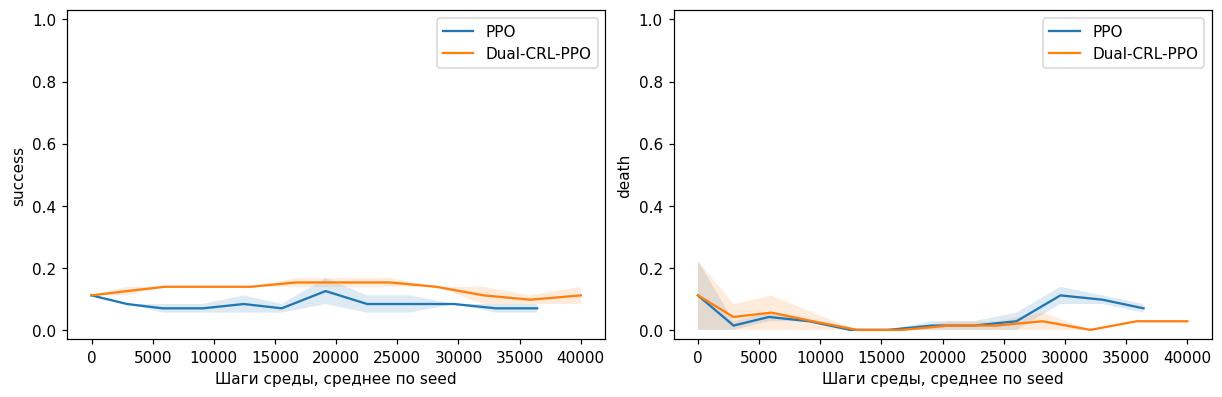

In [15]:
ppo_results={}
started=time.time()
for dual in [False,True]:
    name="Dual-CRL-PPO" if dual else "PPO"
    ppo_results[name]=[]
    for seed in SEEDS:
        run=train_ppo(hard,seed=seed,dual=dual,iterations=PPO_ITERATIONS)
        ppo_results[name].append(run)
        print(f"{name}: seed={seed}, success={run['final']['success']:.2f}, "
              f"death={run['final']['death']:.2f}, шаги={run['steps']}",flush=True)
print(f"PPO-эксперимент: {(time.time()-started)/60:.1f} мин.")

fig,axes=plt.subplots(1,2,figsize=(11,3.5),constrained_layout=True)
for name,runs in ppo_results.items():
    x=np.mean([[h["step"] for h in r["history"]] for r in runs],axis=0)
    for ax,key in zip(axes,["success","death"]):
        y=np.array([[h[key] for h in r["history"]] for r in runs]);mean=y.mean(0);std=y.std(0)
        ax.plot(x,mean,label=name);ax.fill_between(x,np.clip(mean-std,0,1),np.clip(mean+std,0,1),alpha=.15)
        ax.set(xlabel="Шаги среды, среднее по seed",ylabel=key,ylim=(-.03,1.03))
        ax.legend()
plt.show()

## 10. Лаборатория: меняем параметры и наблюдаем механизм

Вызовите `launch_widgets()` в активном Jupyter, чтобы открыть ползунки.
Статический пример ниже выполняется автоматически. Ползунки меняют **формулу меток**, без переобучения. Это быстрый способ отделить математическое действие параметра от шума оптимизации. В траектории есть ранняя цель A, поздняя B и смерть.

- `gamma` ↑: более далёкое будущее получает больше веса; горизонт примерно $1/(1-γ)$.
- `gamma_term` ↑: штраф за смерть распространяется дальше назад.
- `k_max` ↓: меньше будущего, дешевле вычисления, но больше усечения.

Инспектор состояния меняет **вход уже обученного критика**. Он не переобучает сеть при изменении состояния. Для изменения самого агента используйте `run_custom` ниже.

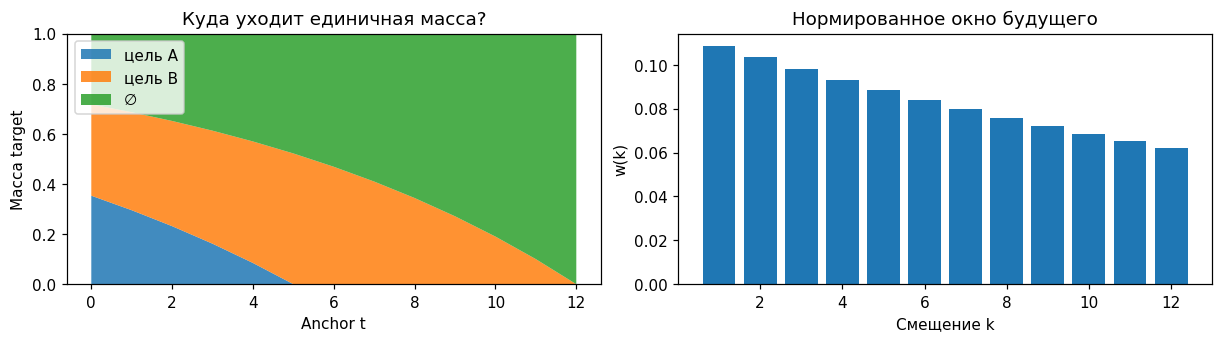

In [16]:
def target_lab(gamma=.95,gamma_term=.9,k_max=12):
    seq=np.zeros((13,2));seq[:5,0]=1;seq[5:12,1]=1  # последняя строка — смерть
    y,_=make_targets(seq,True,gamma=gamma,gamma_term=gamma_term,k_max=k_max)
    fig,axes=plt.subplots(1,2,figsize=(11,3),constrained_layout=True)
    axes[0].stackplot(range(13),y.T,labels=["цель A","цель B","∅"],alpha=.85)
    axes[0].set(xlabel="Anchor t",ylabel="Масса target",ylim=(0,1),title="Куда уходит единичная масса?")
    axes[0].legend(loc="upper left")
    offsets=np.arange(1,k_max+1);weights=gamma**(offsets-1);weights/=weights.sum()
    axes[1].bar(offsets,weights);axes[1].set(xlabel="Смещение k",ylabel="w(k)",title="Нормированное окно будущего")
    plt.show()

target_lab()
def launch_widgets():
    try:
        import ipywidgets as widgets
        display(widgets.interactive(target_lab,
            gamma=widgets.FloatSlider(value=.95,min=.5,max=.995,step=.005,description="γ",continuous_update=False),
            gamma_term=widgets.FloatSlider(value=.9,min=0,max=.995,step=.005,description="γ term",continuous_update=False),
            k_max=widgets.IntSlider(value=12,min=1,max=12,description="k max",continuous_update=False)))
        def explore_state(state=near_lava,goal=challenge_goal):
            inspect_critic(hard,teacher,state,goal)
        display(widgets.interactive(explore_state,
            state=widgets.IntSlider(value=near_lava,min=0,max=hard.n_states-1,description="state id",continuous_update=False),
            goal=widgets.Dropdown(options=[(n,i) for i,n in enumerate(hard.goal_names)],value=challenge_goal,description="Цель")))
    except ImportError:
        print("Виджеты не установлены; вызовите target_lab(...) и inspect_critic(...) вручную.")

# Выполните в активном Jupyter frontend, чтобы открыть ползунки:
# launch_widgets()

### Анимация траектории

Анимация по умолчанию показывает заранее выбранную семантическую цель «есть ключ», seed 0. Можно заменить её на «выход с инструментом», PPO-политику или oracle. Если агент зациклился или умер, это тоже видимый результат. Строка состояния показывает, как меняются инвентарь и здоровье. Крестик обозначает место начала смертельного действия; сама лава не входит в живую траекторию.

In [17]:
def animate_policy(w,policy,goal,horizon=40):
    path,actions,died,success=rollout_path(w,policy,goal,horizon=horizon)
    fig,ax=plt.subplots(figsize=(6,4))
    def update(frame):
        ax.clear()
        i=min(frame,len(path)-1);s=path[i]
        draw_world(w,ax,state=s,path=path[:i+1],goal=goal)
        x,y,key,wood,tool,hp=w.states[s]
        ax.set_title(f"{w.goal_names[goal]} | t={i} | key={key} wood={wood} tool={tool} hp={hp}")
        if died and frame==len(path):
            ax.scatter(x,y,marker="x",s=250,c="red",linewidths=3)
            ax.set_title(ax.get_title()+" | смерть")
        return []
    ani=animation.FuncAnimation(fig,update,frames=len(path)+int(died),interval=220,blit=False)
    html=ani.to_jshtml();plt.close(fig)
    print("Успех:",success,"| смерть:",died,"| действий:",len(actions))
    return HTML(html)

display(animate_policy(hard,lambda s,g:teacher_scores[s,:,g].argmax(),hard.goal_id("есть ключ")))
# Для сравнения на тех же весах (это правило p, а не f из статьи):
# display(animate_policy(hard,lambda s,g:teacher_probs[s,:,g].argmax(),hard.goal_id("есть ключ")))

Успех: False | смерть: False | действий: 40


Чтобы рассмотреть сложную цепочку действий без ошибок обученного агента, ниже анимируется **oracle-планировщик**: он берёт ключ и древесину, создаёт инструмент, открывает путь к выходу. Это визуализация правил MiniCraft, не результат обучения. Никакие его действия не передаются CRL или PPO.

In [18]:
oracle_policy = {s:a for s,a in zip(oracle_path[:-1],oracle_actions)}
display(animate_policy(hard,lambda s,g:oracle_policy.get(s,5),challenge_goal,horizon=40))

# Пример анимации обученного агента простой среды:
# grid = worlds["Grid"]
# grid_scores, _ = critic_table(results[("Grid","CRL")][0]["model"], grid)
# display(animate_policy(grid, lambda s,g: grid_scores[s,:,g].argmax(),
#                        grid.goal_id("клетка (5,3)")))

Успех: True | смерть: False | действий: 17


### Карта поведения при фиксированном инвентаре

Стрелка — greedy action, фон — предсказанный $p(∅)$ для выбранного действия. Кружок — взаимодействовать, точка — ждать. Серые пустые клетки означают, что такой срез состояния не достижим. Высокая точность на посещённых состояниях ничего не говорит об остальных; проверяйте coverage.

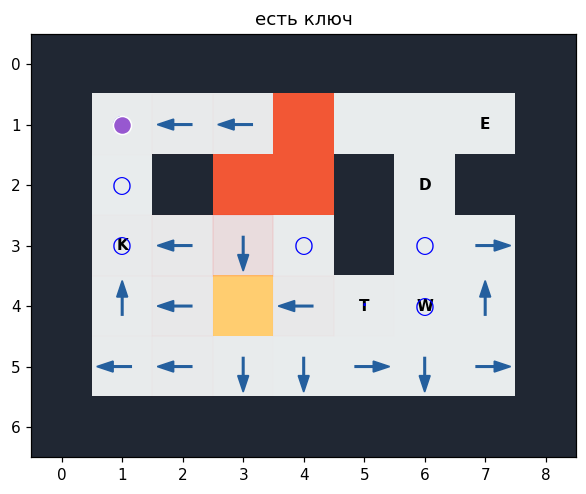

In [19]:
def policy_map(w,model,goal,key=0,wood=0,tool=0,hp=3):
    scores,probs=critic_table(model,w)
    fig,ax=plt.subplots(figsize=(7,5));draw_world(w,ax,state=0,title=w.goal_names[goal])
    for x,y in w.cells:
        s=w.index.get((x,y,key,wood,tool,hp))
        if s is None: continue
        a=int(scores[s,:,goal].argmax())
        residual=probs[s,a,-1] if model.absorbing else 0.0
        ax.add_patch(plt.Rectangle((x-.5,y-.5),1,1,color="red",alpha=.65*residual))
        if a<4:
            dx,dy=w.moves[a];ax.arrow(x-.15*dx,y-.15*dy,.3*dx,.3*dy,width=.025,color="#245f9e",head_width=.18)
        else:
            ax.text(x,y,"○" if a==4 else "·",ha="center",va="center",color="blue",fontsize=15)
    plt.show()

policy_map(hard,teacher,hard.goal_id("есть ключ"))

## 11. Как меняется цена при добавлении тысяч целей?

Для нашей табличной модели: $N_s A d + Gd$ параметров; без факторизации независимая таблица оценок требует $N_sAG$. У нейросетевой версии вместо $N_sAd$ будет общая сеть и action projection. При фиксированном $d$ рост goal-части линейный с небольшим коэффициентом, **не нулевой**.

Полный softmax всё равно требует логитов всех $G$ целей: память и вычисления обучения не становятся независимыми от $G$. Предикаты тоже нужно вычислять. График ниже — **аналитический подсчёт параметров**, а не измерение скорости и не воспроизведение заявленных в статье 38× FLOPs.

У нас `nn.Embedding(G,d)` умеет только известные goal ID. Для новых семантических целей без переобучения понадобился бы энкодер описания/маски предиката; эта способность статьи здесь не реализована.

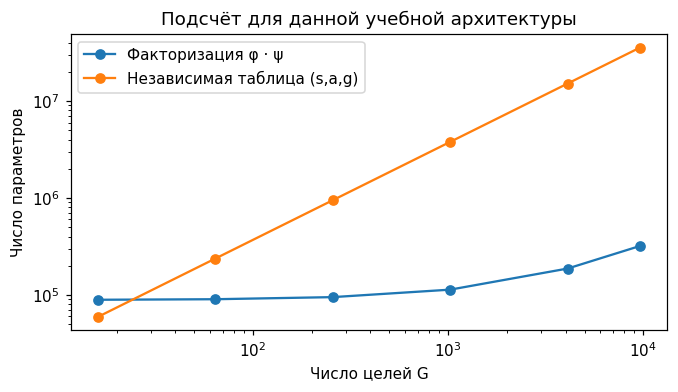

Параметров критика MiniCraft: 89568 | целей: 36


In [20]:
goal_counts=np.array([16,64,256,1024,4096,9637])
N,A,d=hard.n_states,hard.n_actions,BASE.dim
factorized=N*A*d+goal_counts*d
independent=N*A*goal_counts
fig,ax=plt.subplots(figsize=(7,3.5))
ax.loglog(goal_counts,factorized,"o-",label="Факторизация φ · ψ")
ax.loglog(goal_counts,independent,"o-",label="Независимая таблица (s,a,g)")
ax.set(xlabel="Число целей G",ylabel="Число параметров",title="Подсчёт для данной учебной архитектуры")
ax.legend();plt.show()
actual=sum(p.numel() for p in teacher.parameters())
assert actual==N*A*d+hard.G*d
print("Параметров критика MiniCraft:",actual,"| целей:",hard.G)

## 12. Эксперименты для самостоятельной работы

Меняйте **одну настройку за раз**, фиксируйте набор seed и бюджет. `run_custom` не запускается автоматически: раскомментируйте примеры. Чтобы сохранить графики после эксперимента, сохраните сам notebook.

| Изменение | Что проверить | Возможная причина результата |
|:--|:--|:--|
| `rb=False` | Шум loss и разброс seed | Семплируется один будущий offset |
| `gamma_term=0 / .5 / .9 / .98` | Success **и** death | Дальность штрафа за смерть |
| `gamma=.8 / .95 / .99` | Дальние цели vs близкие | Эффективный горизонт |
| `k_max=4 / 16 / 64` | Длинная цепочка крафта | Усечение будущего |
| `dim=4 / 16 / 64` | Недообучение vs стоимость | Ограниченный ранг матрицы логитов |
| `epsilon_end=.02 / .2 / .5` | Покрытие состояний и новых целей | Исследование против эксплуатации |
| `replay_size=1500 / 25000` | Адаптация к новой политике | Устаревшие continuation policies |
| `action_score="probability"` | Логиты vs нормированные массы | Разная нормировка между действиями |
| `beta0=0 / .1 / .4 / 1` в `train_ppo` | Когда teacher помогает/мешает | Качество teacher и сила distillation |

Для быстрого эксперимента можно уменьшить `rounds`, но это сокращает бюджет. Для вывода об эффекте настройки нужны несколько seed. Для сравнения по шагам среды, а не по эпизодам, понадобится отдельный stop condition по числу transitions.

In [21]:
def run_custom(env_name="MiniCraft", seeds=(0,1), **changes):
    w=worlds[env_name];runs=[]
    for seed in seeds:
        cfg=replace(BASE,seed=seed,**changes)
        run=train_crl(w,cfg);runs.append(run)
        print("seed",seed,"success",round(run["final"]["success"],3),
              "death",round(run["final"]["death"],3),"покрытие",round(run["state_coverage"],3))
    fig,axes=plt.subplots(1,2,figsize=(10,3))
    for run in runs:
        for ax,key in zip(axes,["success","death"]):
            ax.plot([h["step"] for h in run["history"]],[h[key] for h in run["history"]],label=f"seed {run['cfg'].seed}")
            ax.set(xlabel="Шаги среды",ylabel=key,ylim=(-.03,1.03));ax.legend()
    plt.show()
    return runs

# Мало данных: быстрая проверка (будет хуже основной конфигурации).
# my_runs = run_custom(rounds=15, gamma_term=.5, k_max=16)
# Один будущий offset вместо RB:
# sampled_runs = run_custom(rb=False)
# Другая шкала выбора действия (отклонение от политики статьи):
# probability_runs = run_custom(action_score="probability")

### Глубокие вопросы и короткие ответы

**Почему не BCE по каждой цели?** Можно сделать другой алгоритм с независимыми вероятностями. Здесь categorical softmax и равномерное деление метки согласованы с конкретной занятостью из формулы 5. BCE меняет задачу и численный смысл критика.

**Почему нельзя просто дать штраф −1 за смерть?** Это допустимая другая постановка RL, но CRL учит классификацию будущих целей без reward. Absorbing class делает смерть частью распределения меток сразу для всех целей.

**Если выживание выросло, почему успех может снизиться?** Политика может слишком избегать риска, а задачи требуют долгого исследования. Success «хотя бы раз» и нормированная discounted occupancy тоже различаются. Результаты статьи прямо показывают этот компромисс.

**RB убирает весь шум?** Нет. Он интегрирует offset и уже известные семантические метки при фиксированной траектории. Случайность среды, исследование, конечный датасет и SGD остаются.

**Откуда берётся градиент на смертельном действии?** При $y_\varnothing=1$ loss равен $\log(1+\sum_g e^{f_g})$. Его производная по каждому $f_g$ равна $p_g>0$, поэтому gradient descent снижает все goal-логиты fatal action. Фиксированный нулевой logit ∅ задаёт общий масштаб.

**Что если ни один предикат не выполнен?** Вектор $\ell$ нулевой, а остаточная масса идёт в ∅. Тогда ∅ объединяет отсутствие семантических целей и поглощение; его нельзя называть «детектором смерти». В наших средах клеточная цель всегда выполнена, поэтому этот случай проверен отдельно искусственной меткой.

**Есть ли гарантия достижения любой цели?** Нет. Нужны покрытие данных, достаточная ёмкость, оптимизация и подходящий continuation policy. Комбинаторные дальние цели могут не открыться вообще. Табличные эмбеддинги не обеспечивают обобщения на новые состояния.

**Что перенести в Craftax?** Симулятор и предикаты заменить на Craftax, $\phi$ — на энкодер символического наблюдения, сбор — на векторизованные rollout. Нужно восстановить scheduler, маски episode/window, архитектуру, hyperparameters и бюджет статьи; это отдельный полноценный reproduction project.

### Соответствие исходной статье и ограничения

| Компонент статьи | Здесь |
|:--|:--|
| Eq. 3–5: semantic goals, categorical CE | `World.goals`, `World.labels`, soft CE |
| Eq. 6: Rao–Blackwell по будущим offset | `make_targets(rb=True)` |
| Eq. 7: absorbing class с logit=0 | `CRLCritic.class_logits` |
| Eq. 8: termination-discounted targets | `make_targets`, отдельно от time-limit |
| Eq. 9: PPO + annealed behavioral cloning | `train_ppo(dual=True)`, joint teacher/student |
| 136–9637 целей Craftax, JAX, H100 | Не воспроизводится; две CPU-среды |
| Обобщение goal-encoder на новые предикаты | Не реализовано: здесь goal-ID embedding |
| Масштабные seed/FLOPs-выводы | Не заявляются; 2 seed и аналитический подсчёт |

**Источник:** приложенный PDF, §2–3 (формулы 1–9), §4, Appendix B. Это разбор предоставленной рукописи, без утверждения о её принятии или независимой проверке опубликованных результатов. Инструкции для рецензентов в колонтитулах PDF не относятся к нашей задаче и не используются как команды.

In [22]:
# Короткий машинный отчёт: полезно после «Restart kernel & Run all».
assert all(len(r["history"])>=2 and np.isfinite(r["final"]["success"])
           for runs in results.values() for r in runs)
assert all(r["steps"]>0 for runs in ppo_results.values() for r in runs)
check_targets()
print("Обучено CRL-моделей:",sum(map(len,results.values())))
print("Обучено PPO-политик:",sum(map(len,ppo_results.values())))
print("Все численные эксперименты завершены; оценка выполнена на всех целях обеих сред.")
print("Результаты относятся к указанным seed, картам и бюджету; это не метрики Craftax.")

Проверки меток: 7 смысловых инвариантов выполнены.
Обучено CRL-моделей: 10
Обучено PPO-политик: 4
Все численные эксперименты завершены; оценка выполнена на всех целях обеих сред.
Результаты относятся к указанным seed, картам и бюджету; это не метрики Craftax.
